<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_13/dataset_pbl/praktikum_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 3**
Praktikum 3 kali ini kita akan mencoba menggunakan Keras untuk Regresi, khususnya pada kasus Prediksi durasi tidur.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# 1. Load dataset Sleep Health
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

X = df[['Stress Level']]
y = df[['Sleep Duration']]

# 2. Normalisasi
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# 3. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42
)

# 4. Model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100, verbose=0)

# 5. Evaluasi dan kembalikan ke skala jam asli
prediksi_scaled = model.predict(X_test)
prediksi_jam = scaler_y.inverse_transform(prediksi_scaled)
print("Contoh Prediksi Durasi Tidur (jam):", prediksi_jam[:5].flatten())

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Contoh Prediksi Durasi Tidur (jam): [7.7563176 6.0472636 6.0472636 7.7563176 6.0472636]


## **TUGAS 4**
- Ubah learning rate.
- Bandingkan hasil loss.



In [ ]:
learning_rates = [0.1, 0.01, 0.001]

for lr in learning_rates:
    model_lr = tf.keras.Sequential([
        tf.keras.Input(shape=(1,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1)
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    model_lr.compile(optimizer=optimizer, loss='mse')

    history = model_lr.fit(X_train, y_train, epochs=100, verbose=0)
    final_loss = history.history['loss'][-1]
    print(f"Learning Rate: {lr} -> Final Loss (MSE): {final_loss:.4f}")

Learning Rate: 0.1 -> Final Loss (MSE): 0.1723
Learning Rate: 0.01 -> Final Loss (MSE): 0.1526
Learning Rate: 0.001 -> Final Loss (MSE): 0.3085


### Hasil Perbandingan

* **Learning Rate 0.001 (Default)**  
  **Nilai MSE Loss:** 0.3085  
  Perubahan bobot terjadi secara sangat lambat. Dalam batas 100 epoch, proses optimasi belum sempat mencapai titik minimum terbaik untuk memetakan hubungan tingkat stres dan durasi tidur, sehingga nilai loss masih relatif tinggi.

* **Learning Rate 0.01**  
  **Nilai MSE Loss:** 0.1526  
  Kecepatan pembaruan bobot berada pada titik paling optimal. Loss mampu turun secara drastis dibanding konfigurasi default dalam jumlah epoch yang sama.

* **Learning Rate 0.1**  
  **Nilai MSE Loss:** 0.1723  
  Proses konvergensi berlangsung sangat cepat di awal iterasi, tetapi langkah pembaruan bobot yang terlalu besar sedikit melompati titik minimum optimal pada variasi data alami Sleep Health, sehingga nilai loss akhirnya sedikit lebih tinggi dibanding learning rate 0.01.

**Kesimpulan Utama**  
Pada eksperimen regresi dataset Sleep Health ini, penggunaan **learning rate 0.01** memberikan kinerja terbaik dengan kesalahan prediksi (MSE Loss) terkecil sebesar **0.1526**.

Praktikum berikut akan menggunakan model Multi-Layer Perceptron (MLP) dengan seluruh fitur numerik pada dataset Sleep Health untuk memprediksi durasi tidur.

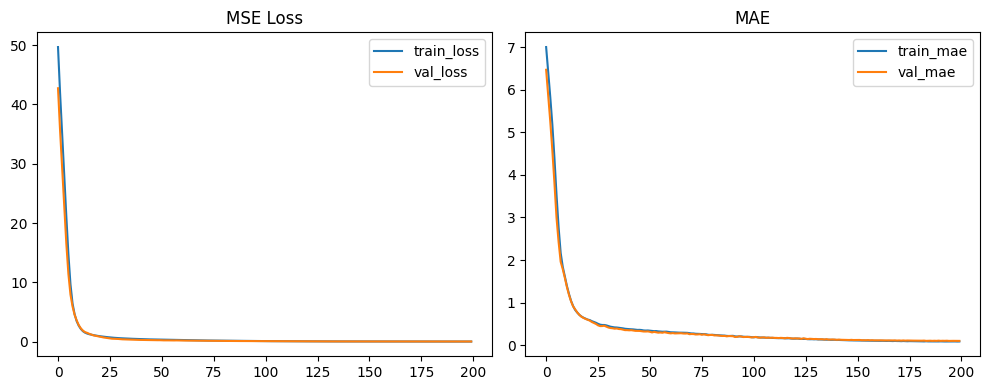

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
RMSE Prediksi Durasi Tidur: 0.1546 jam


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# 1. Load fitur numerik dari dataset Sleep Health
fitur = [
    'Age', 'Quality of Sleep', 'Physical Activity Level',
    'Stress Level', 'Heart Rate', 'Daily Steps'
]
X_multi = df[fitur].values
y_multi = df['Sleep Duration'].values

# 2. Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X_multi)
X_train, X_val, y_train, y_val = train_test_split(
    Xs, y_multi, test_size=0.2, random_state=42
)

# 3. Build model MLP
model_mlp = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

model_mlp.compile(
    optimizer=Adam(1e-3),
    loss='mse',
    metrics=['mae']
)

# 4. Train
history = model_mlp.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    verbose=0
)

# 5. Plot grafik Loss dan MAE
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('MSE Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='train_mae')
plt.plot(history.history['val_mae'], label='val_mae')
plt.title('MAE')
plt.legend()

plt.tight_layout()
plt.show()

# 6. Evaluasi RMSE
pred = model_mlp.predict(X_val).ravel()
rmse = np.sqrt(np.mean((pred - y_val) ** 2))
print(f"RMSE Prediksi Durasi Tidur: {rmse:.4f} jam")